# Produce Prices
## Data Exploration & Analysis

### Project Objective
The goal of this project is to investigate produce prices trends over time.

### Imports and setup

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Search the current folder and its parent folders.
search_roots = [Path.cwd(), *Path.cwd().parents]

candidate_names = [
    "kroger_produce_cleaned.csv",
    "kroger_produce_raw.csv",
]

DATA_PATH = None

for name in candidate_names:
    for root in search_roots:
        matches = list(root.glob(f"data/**/{name}"))
        if matches:
            DATA_PATH = matches[0]
            break
    if DATA_PATH is not None:
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find kroger_produce_cleaned.csv or "
        "kroger_produce_raw.csv. Set DATA_PATH manually."
    )

print("Using dataset:", DATA_PATH)

Using dataset: /mnt/c/Users/benny/csci_code/csci_413/produce-recommender/data/processed/kroger_produce_cleaned.csv


### Load and Inspect Data

In [3]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())
display(df.dtypes.to_frame("Data type"))

Dataset shape: (316, 12)

Column names:
['search_term', 'product_id', 'upc', 'description', 'brand', 'size', 'regular_price', 'promo_price', 'store_id', 'collection_date', 'collection_timestamp', 'store_name']


,search_term,product_id,upc,description,brand,size,regular_price,promo_price,store_id,collection_date,collection_timestamp,store_name
0,bananas,4011,4011,Fresh Bunch of Bananas – 5-7 Bananas,Fresh Bananas,1 lb,0.55,NaN,62000019,2026-10-15,NaN,NaN
1,bananas,94011,94011,Fresh Bunch of Organic Bananas – 5-7 Bananas,Fresh Bananas,1 lb,0.79,NaN,62000019,2026-10-15,NaN,NaN
2,bananas,4235,4235,Fresh Plantain - Single,NaN,1 ea,0.67,NaN,62000019,2026-10-15,NaN,NaN
3,bananas,8259219415,8259219415,Naked Boosted Smoothie Strawberry Banana Machine,Naked,15.2 fl oz,3.79,NaN,62000019,2026-10-15,NaN,NaN
4,bananas,8259219464,8259219464,Naked Boosted Smoothie Strawberry Banana Machine,Naked,64 fl oz,8.99,NaN,62000019,2026-10-15,NaN,NaN


,Data type
search_term,str
product_id,int64
upc,int64
description,str
brand,str
size,str
regular_price,float64
promo_price,float64
store_id,int64
collection_date,str


### Dataset Overview & Statistics

In [4]:
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Exact duplicate rows:", df.duplicated().sum())

quality_summary = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True),
})

display(quality_summary)

print("\nNumeric descriptive statistics:")
display(df.describe(include=[np.number]).T)

print("\nMissing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("Missing values"))

Rows: 316
Columns: 12
Exact duplicate rows: 0


,data_type,missing_count,missing_percent,unique_values
search_term,str,0,0.00,8
product_id,int64,0,0.00,93
upc,int64,0,0.00,93
description,str,0,0.00,90
brand,str,96,30.38,17
size,str,0,0.00,28
regular_price,float64,1,0.32,44
promo_price,float64,267,84.49,13
store_id,int64,0,0.00,3
collection_date,str,237,75.00,1



Numeric descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
product_id,316.0,6.647019e+09,2.076198e+10,3082.00,4689.00,1.111060e+09,1.111092e+09,8.500765e+10
upc,316.0,6.647019e+09,2.076198e+10,3082.00,4689.00,1.111060e+09,1.111092e+09,8.500765e+10
regular_price,315.0,3.134190e+00,1.864069e+00,0.55,1.69,2.790000e+00,3.990000e+00,8.990000e+00
promo_price,49.0,2.644490e+00,1.298748e+00,1.67,1.99,2.190000e+00,2.690000e+00,6.990000e+00
store_id,316.0,6.200005e+07,3.692563e+01,62000019.00,62000019.00,6.200004e+07,6.200007e+07,6.200011e+07



Missing values by column:


,Missing values
promo_price,267
collection_date,237
brand,96
collection_timestamp,79
store_name,79
regular_price,1
product_id,0
search_term,0
description,0
upc,0


### Price Columns setup

In [5]:
price_columns = ["regular_price", "promo_price"]

for col in price_columns:
    if col not in df.columns:
        df[col] = np.nan

    df[col] = pd.to_numeric(df[col], errors="coerce")

    # Treat zero and negative prices as invalid.
    df.loc[df[col] <= 0, col] = np.nan

has_regular = df["regular_price"].notna()
has_promo = df["promo_price"].notna()

valid_discount = (
    has_regular
    & has_promo
    & (df["promo_price"] < df["regular_price"])
)

df["effective_price"] = df["regular_price"]
df.loc[valid_discount, "effective_price"] = df.loc[
    valid_discount, "promo_price"
]

df["discount_amount"] = np.where(
    valid_discount,
    df["regular_price"] - df["promo_price"],
    np.nan,
)

df["discount_percent"] = np.where(
    valid_discount,
    (df["discount_amount"] / df["regular_price"]) * 100,
    np.nan,
)

print("Rows with valid regular prices:", has_regular.sum())
print("Rows with valid promotional prices:", has_promo.sum())
print("Rows with a valid lower promotional price:", valid_discount.sum())
print("Rows with a usable effective price:", df["effective_price"].notna().sum())

display(df[
    ["description", "regular_price", "promo_price",
     "effective_price", "discount_amount", "discount_percent"]
].head(10))

Rows with valid regular prices: 315
Rows with valid promotional prices: 49
Rows with a valid lower promotional price: 48
Rows with a usable effective price: 315


,description,regular_price,promo_price,effective_price,discount_amount,discount_percent
0,Fresh Bunch of Bananas – 5-7 Bananas,0.55,NaN,0.55,NaN,NaN
1,Fresh Bunch of Organic Bananas – 5-7 Bananas,0.79,NaN,0.79,NaN,NaN
2,Fresh Plantain - Single,0.67,NaN,0.67,NaN,NaN
3,Naked Boosted Smoothie Strawberry Banana Machine,3.79,NaN,3.79,NaN,NaN
4,Naked Boosted Smoothie Strawberry Banana Machine,8.99,NaN,8.99,NaN,NaN
5,Simple Truth® Freeze-Dried Bananas,4.99,NaN,4.99,NaN,NaN
6,Simple Truth® Berries and Banana Trail Mix,8.99,NaN,8.99,NaN,NaN
7,Bare® Baked Crunchy Simply Banana Chips Dried ...,6.29,NaN,6.29,NaN,NaN
8,Banana Squash,NaN,NaN,NaN,NaN,NaN
9,Large Honeycrisp Apple – Each,2.49,2.19,2.19,0.3,12.048193


In [6]:
price_stats = df[
    ["regular_price", "promo_price", "effective_price"]
].agg(
    ["count", "mean", "median", "std", "min", "max"]
).T

price_stats["Q1"] = df[
    ["regular_price", "promo_price", "effective_price"]
].quantile(0.25)

price_stats["Q3"] = df[
    ["regular_price", "promo_price", "effective_price"]
].quantile(0.75)

display(price_stats.round(2))

,count,mean,median,std,min,max,Q1,Q3
regular_price,315.0,3.13,2.79,1.86,0.55,8.99,1.69,3.99
promo_price,49.0,2.64,2.19,1.30,1.67,6.99,1.99,2.69
effective_price,315.0,3.04,2.49,1.85,0.55,8.99,1.69,3.99


### Price Distribution

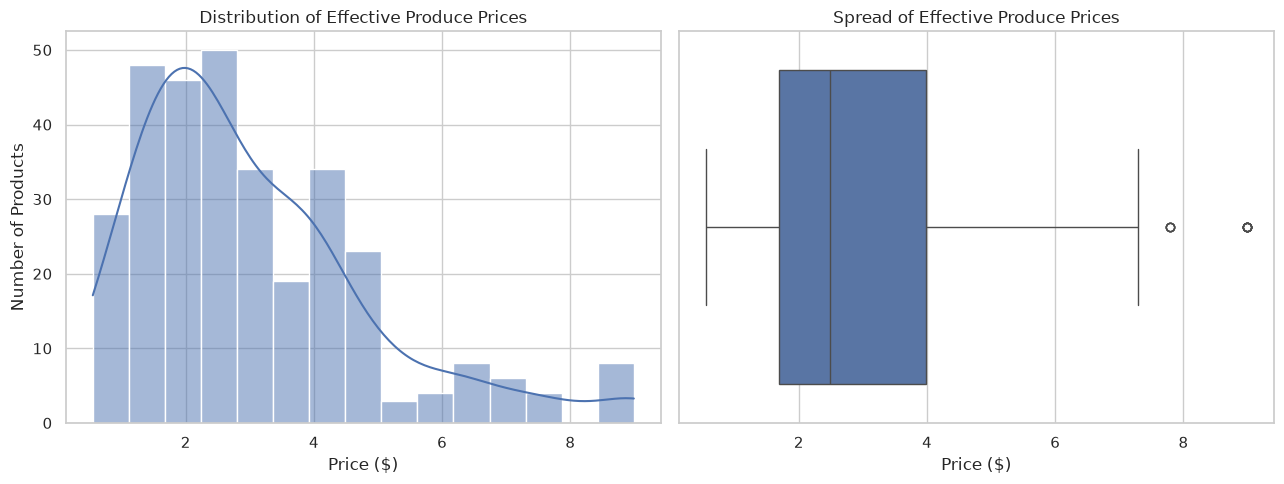

In [7]:
prices = df["effective_price"].dropna()

if prices.empty:
    print("No valid prices available to plot.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    sns.histplot(prices, bins=15, kde=True, ax=axes[0])
    axes[0].set_title("Distribution of Effective Produce Prices")
    axes[0].set_xlabel("Price ($)")
    axes[0].set_ylabel("Number of Products")

    sns.boxplot(x=prices, ax=axes[1])
    axes[1].set_title("Spread of Effective Produce Prices")
    axes[1].set_xlabel("Price ($)")

    plt.tight_layout()
    plt.show()

### Extremity Values

10 cheapest products by listed package price:


,description,search_term,brand,size,regular_price,promo_price,effective_price
0,Fresh Bunch of Bananas – 5-7 Bananas,bananas,Fresh Bananas,1 lb,0.55,NaN,0.55
237,Fresh Bunch of Bananas – 5-7 Bananas,bananas,Fresh Bananas,1 lb,0.55,NaN,0.55
79,Fresh Bunch of Bananas – 5-7 Bananas,bananas,Fresh Bananas,1 lb,0.55,NaN,0.55
158,Fresh Bunch of Bananas – 5-7 Bananas,bananas,Fresh Bananas,1 lb,0.55,NaN,0.55
81,Fresh Plantain - Single,bananas,NaN,1 ea,0.67,NaN,0.67
2,Fresh Plantain - Single,bananas,NaN,1 ea,0.67,NaN,0.67
160,Fresh Plantain - Single,bananas,NaN,1 ea,0.67,NaN,0.67
239,Fresh Plantain - Single,bananas,NaN,1 ea,0.67,NaN,0.67
15,Small Gala Apple – Each,apples,Fresh Apples,1 each,0.75,NaN,0.75
174,Small Gala Apple – Each,apples,Fresh Apples,1 each,0.75,NaN,0.75


10 most expensive products by listed package price:


,description,search_term,brand,size,regular_price,promo_price,effective_price
6,Simple Truth® Berries and Banana Trail Mix,bananas,Simple Truth,16 oz,8.99,NaN,8.99
244,Naked Boosted Smoothie Strawberry Banana Machine,bananas,Naked,64 fl oz,8.99,NaN,8.99
4,Naked Boosted Smoothie Strawberry Banana Machine,bananas,Naked,64 fl oz,8.99,NaN,8.99
243,Simple Truth® Berries and Banana Trail Mix,bananas,Simple Truth,16 oz,8.99,NaN,8.99
84,Simple Truth® Berries and Banana Trail Mix,bananas,Simple Truth,16 oz,8.99,NaN,8.99
164,Simple Truth® Berries and Banana Trail Mix,bananas,Simple Truth,16 oz,8.99,NaN,8.99
165,Naked Boosted Smoothie Strawberry Banana Machine,bananas,Naked,64 fl oz,8.99,NaN,8.99
86,Naked Boosted Smoothie Strawberry Banana Machine,bananas,Naked,64 fl oz,8.99,NaN,8.99
264,Kroger® Gold Potatoes,potatoes,Fresh Potatoes,5 lb,7.79,NaN,7.79
106,Kroger® Gold Potatoes,potatoes,Fresh Potatoes,5 lb,7.79,NaN,7.79


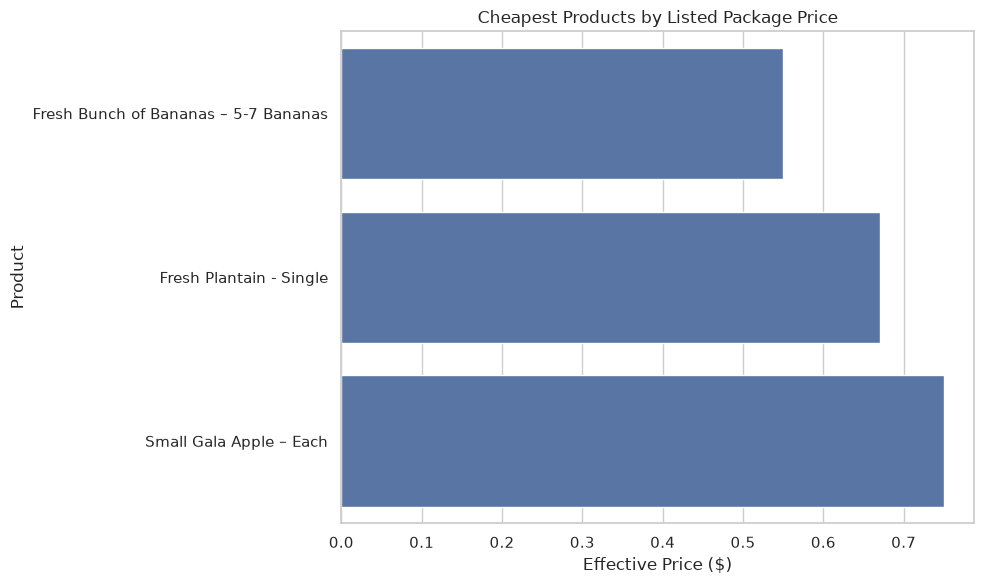

In [8]:
description_col = (
    "description" if "description" in df.columns
    else "product_id" if "product_id" in df.columns
    else df.columns[0]
)

comparison_columns = [
    col for col in [
        description_col, "search_term", "brand", "size",
        "regular_price", "promo_price", "effective_price"
    ]
    if col in df.columns
]

priced_products = df.dropna(subset=["effective_price"]).copy()

print("10 cheapest products by listed package price:")
display(
    priced_products.sort_values("effective_price")[
        comparison_columns
    ].head(10)
)

print("10 most expensive products by listed package price:")
display(
    priced_products.sort_values("effective_price", ascending=False)[
        comparison_columns
    ].head(10)
)

if not priced_products.empty:
    cheapest = (
        priced_products.nsmallest(10, "effective_price")
        .sort_values("effective_price", ascending=True)
    )

    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=cheapest,
        x="effective_price",
        y=description_col,
    )
    plt.title("Cheapest Products by Listed Package Price")
    plt.xlabel("Effective Price ($)")
    plt.ylabel("Product")
    plt.tight_layout()
    plt.show()

### Promotional Pricing & Comparison

Products with valid lower promotional prices: 48
Average discount (%): 19.6
Median discount (%): 19.08


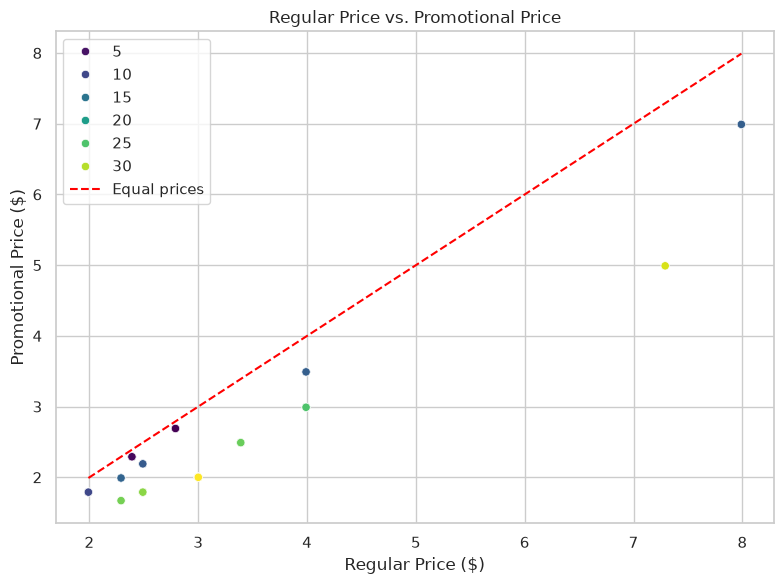

In [9]:
promo_df = df.dropna(
    subset=["regular_price", "promo_price", "discount_percent"]
).copy()

if promo_df.empty:
    print("No valid regular-versus-promotional price pairs to compare.")
else:
    print("Products with valid lower promotional prices:", len(promo_df))
    print(
        "Average discount (%):",
        round(promo_df["discount_percent"].mean(), 2),
    )
    print(
        "Median discount (%):",
        round(promo_df["discount_percent"].median(), 2),
    )

    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        data=promo_df,
        x="regular_price",
        y="promo_price",
        hue="discount_percent",
        palette="viridis",
    )
    plt.plot(
        [promo_df["regular_price"].min(),
         promo_df["regular_price"].max()],
        [promo_df["regular_price"].min(),
         promo_df["regular_price"].max()],
        linestyle="--",
        color="red",
        label="Equal prices",
    )
    plt.title("Regular Price vs. Promotional Price")
    plt.xlabel("Regular Price ($)")
    plt.ylabel("Promotional Price ($)")
    plt.legend()
    plt.tight_layout()
    plt.show()

,count,mean,median,std,min,max
search_term,,,,,,
onions,40,2.11,1.59,1.14,0.99,4.49
bell pepper,40,2.12,1.69,0.96,0.89,3.99
carrots,40,2.14,2.29,0.52,1.29,3.00
potatoes,40,3.55,2.74,2.11,0.89,7.79
tomatoes,40,3.00,2.99,0.80,1.29,5.00
apples,40,3.43,3.64,1.70,0.75,7.29
broccoli,40,3.89,3.74,1.62,1.59,6.99
bananas,35,4.19,3.79,3.29,0.55,8.99


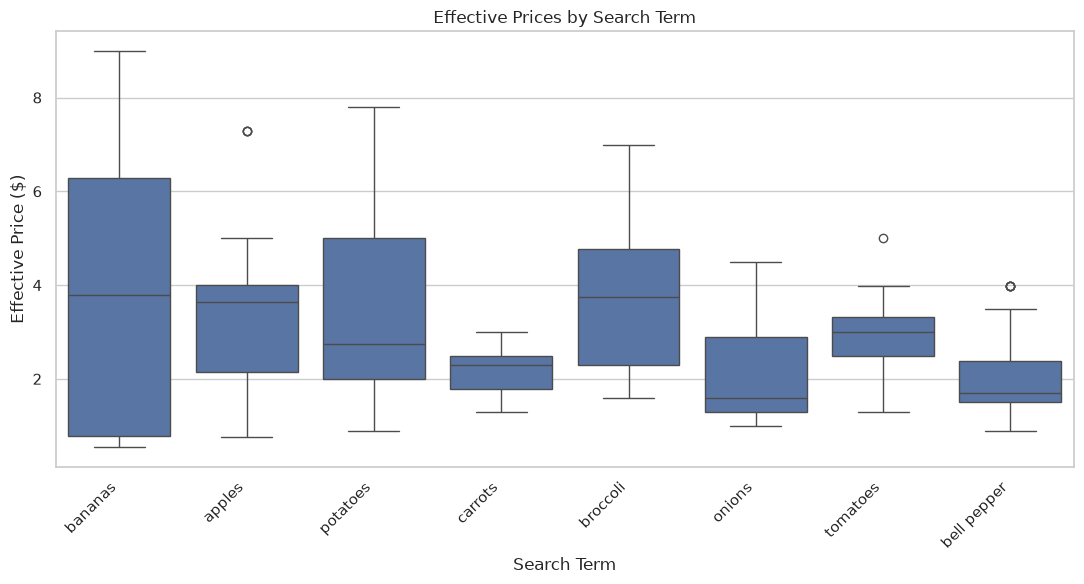

In [10]:
if "search_term" not in df.columns:
    print("No search_term column; category comparison is unavailable.")
else:
    category_summary = (
        df.dropna(subset=["effective_price"])
        .groupby("search_term")["effective_price"]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .round(2)
        .sort_values("median")
    )

    display(category_summary)

    category_data = df.dropna(
        subset=["effective_price", "search_term"]
    )

    if not category_data.empty:
        plt.figure(figsize=(11, 6))
        sns.boxplot(
            data=category_data,
            x="search_term",
            y="effective_price",
        )
        plt.title("Effective Prices by Search Term")
        plt.xlabel("Search Term")
        plt.ylabel("Effective Price ($)")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()